# Efficient calculation of the elctromagnetic fields of an extended source.
## A reproduction of Boerner and West, 1984

In [1]:
# the lamontagne quintic spline...

S1 = lambda x: 1 - (9/4)*x**2 * ( 1 - 2./9*x*(1 + 5/2*x*(1 - 2/5 * x)))
S2 = lambda x: -1/2*x*(1 - 11/6*x*(1 - 2/11*x*(1 + 5/2*x*(1-2/5*x))))

def lamontagne(x):
    phi   = x*0.
    xm2m1 = (-2 <= x)*(x < -1)
    xm1m0 = (-1 <= x)*(x < 0)
    x0p1  = (0 <= x)*(x < 1)
    x1p2  = (1 <= x)*(x < 2)
    
    phi[xm2m1] = S2(-x[xm2m1]-1)
    phi[xm1m0] = S1(-x[xm1m0])
    phi[x0p1] = S1(x[x0p1])
    phi[x1p2] = S2(x[x1p2]-1)
    
    return phi

In [2]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-2, 2, 100)

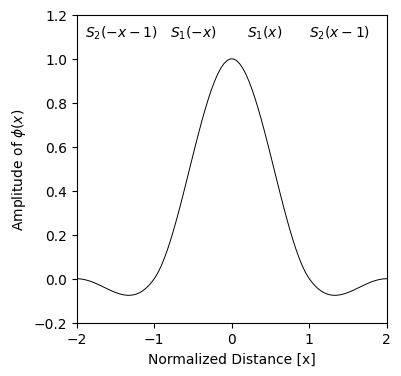

In [3]:
plt.figure(figsize=(4,4))
plt.plot(x, lamontagne(x), 'k-', linewidth=0.7)
plt.text(-1.9, 1.1, '$S_2(-x-1)$')
plt.text(-0.8, 1.1, '$S_1(-x)$')
plt.text(0.2, 1.1, '$S_1(x)$')
plt.text(1, 1.1, '$S_2(x-1)$')
plt.ylabel('Amplitude of $\phi (x)$')
plt.xlabel('Normalized Distance [x]')
plt.ylim(-0.2, 1.2); plt.xlim(-2, 2)
plt.show()

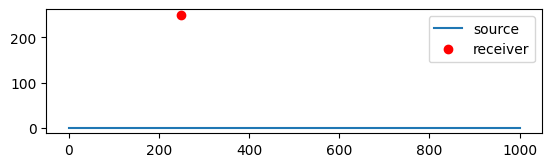

In [4]:
fig,ax = plt.subplots()
ax.plot([0, 1000], [0,0], label='source')
ax.plot([250], [250], 'ro', label='receiver')
ax.set_aspect('equal')
ax.legend()


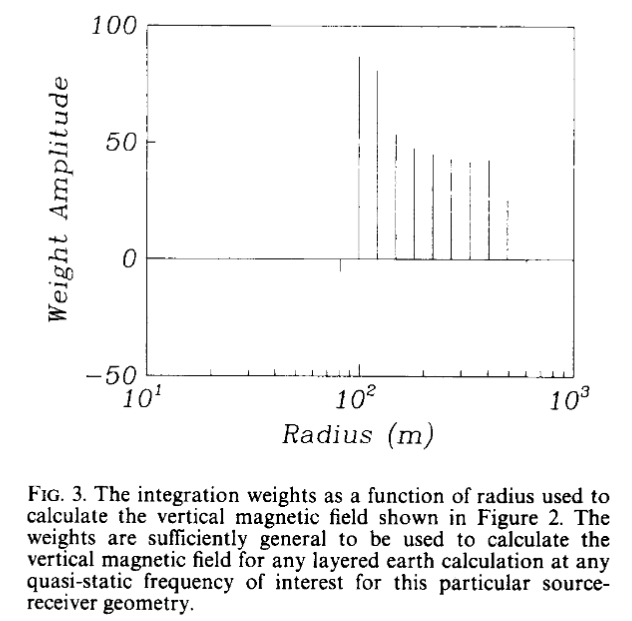

In [270]:
r_k = np.logspace(1, 4, 51)
# r_k = np.linspace(10, 2000, 201)
dr = np.gradient(r_k)

In [271]:
sofr = np.zeros_like(r_k)

In [272]:
x_obs, y_obs = 100,100

x = np.linspace(0.001, 1000, 101)
dx = x[1]-x[0]
allr = np.sqrt((x-x_obs)**2 + y_obs**2)
theta = np.arctan(y_obs, x_obs-x)

dR = r_k[1]/r_k[0]

# logR = np.log10(r_k)
# dr = r_k*np.log(np.array([10], dtype=np.float64))*(logR.max()-logR.min())/len(r_k)

#dr = np.gradient(allr)


for i,cr_k  in enumerate(r_k):
    cphi = np.sin(theta)*lamontagne((np.log(allr)-np.log(cr_k))/np.log(dR))*dx
    # cphi = dx * y_obs * lamontagne((allr-cr_k)/dr[i]) / cr_k
    sofr[i] = np.nansum(cphi)


In [273]:
# sofr = 1000*sofr / sofr.sum()

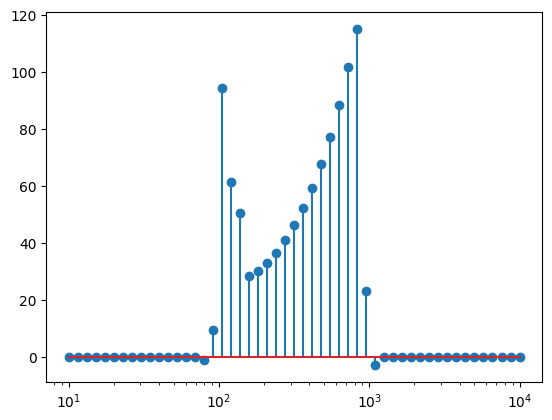

In [274]:
plt.figure()
plt.stem(r_k, sofr)
plt.xscale('log')

In [275]:
from anemone import constants as c

In [276]:
omega = 2*np.pi*np.logspace(-4, 4, 51)

In [277]:
sigma = 1.
gmm = np.sqrt(1j*omega*c.mu0*sigma)
def Hr(rho):
    return (3 - (3 + 3*gmm*rho + gmm**2*rho**2)*np.exp(-gmm*rho))/(2*np.pi*gmm**2*rho**4)

In [278]:
rho = np.sqrt((x-x_obs)**2 + y_obs**2)
theta = np.arctan(y_obs, x_obs-x)

Hz_omega = np.zeros_like(omega, dtype=complex)
Hz_iws = np.zeros_like(omega, dtype=complex)

for i in range(len(x)):
    Hz_omega += Hr(rho[i])*np.sin(theta[i])*dx
    # Hz_omega += Hr(rho[i]*y_obs/rho[i])*dx

for i in range(len(r_k)):
    Hz_iws += Hr(r_k[i])*sofr[i]

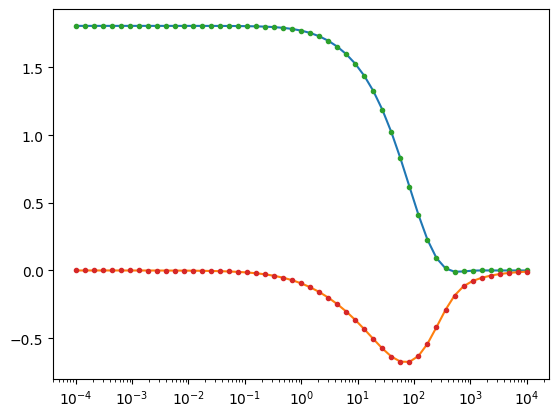

In [279]:
plt.figure()
plt.semilogx(omega/np.pi/2, Hz_omega.real/1e-3)
plt.semilogx(omega/np.pi/2, Hz_omega.imag/1e-3)

plt.semilogx(omega/np.pi/2, Hz_iws.real/1e-3, '.')
plt.semilogx(omega/np.pi/2, Hz_iws.imag/1e-3, '.')

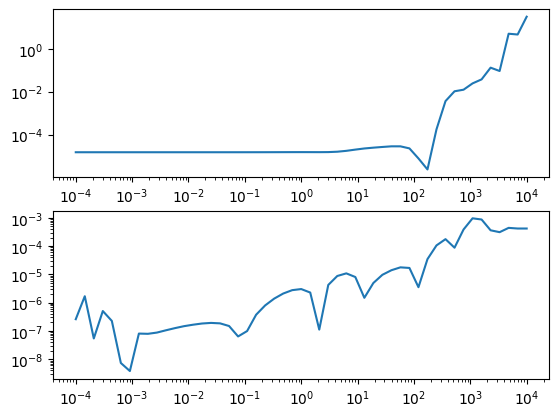

In [280]:
fig,axs = plt.subplots(2,1)
axs[0].loglog(omega/np.pi/2, np.abs(Hz_omega.real-Hz_iws.real)/np.abs(Hz_omega.real))
axs[1].loglog(omega/np.pi/2, np.abs(Hz_omega.imag-Hz_iws.imag)/np.abs(Hz_omega.imag))